# End-to-End Evaluation (V4 -> Reranker -> Causal)

This notebook evaluates the full pipeline end-to-end using weakly labeled (silver) data:
1) Embedding retrieval (V4 cached embeddings)
2) Cross-encoder reranker
3) Causal cross-encoder classifier

**Note**: Silver labels are heuristic. Treat metrics as indicative, not definitive.


In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sentence_transformers import CrossEncoder


In [2]:
# Config
DATA_CSV = Path('data_new/SNow_incident_ticket_data.csv')
EMB_PATH = Path('embeddings_v4_cache.npy')

SILVER_DUP_PATH = Path('docs/labeling/silver_pairs_embedding_neighbors_10000_with_pos.csv')
SILVER_CAUSAL_PATH = Path('docs/labeling/silver_pairs_temporal_24h_10000.csv')
INDEPENDENT_SIGNAL_PATH = Path('docs/labeling/independent_signal_pairs.csv')

RERANKER_MODEL_ID = 'cross-encoder/ms-marco-MiniLM-L-6-v2'
USE_RERANKER = False
CAUSAL_MODEL_PATH = Path('models/causal_classifier/causal_crossencoder_v1')
CAUSAL_METRICS_PATH = CAUSAL_MODEL_PATH / 'evaluation_metrics.json'

# Evaluation settings
K_VALUES = [5, 10, 20, 50]
RERANK_TOP_K = 100
CAUSAL_TOP_N = 10
MAX_DUP_QUERIES = 200
MAX_CAUSAL_QUERIES = 100
RANDOM_SEED = 42

print('OK config loaded')


OK config loaded


In [3]:
# Load data
np.random.seed(RANDOM_SEED)

incidents = pd.read_csv(DATA_CSV)
incidents['Created_dt'] = pd.to_datetime(incidents['Created'], format='%d/%m/%y %H:%M', errors='coerce')
incidents['Description'] = incidents['Description'].fillna('')

def get_desc(idx):
    text = incidents.loc[idx, 'Description']
    return '' if pd.isna(text) else str(text)

embeddings = np.load(EMB_PATH)
embeddings = embeddings.astype(np.float32)
emb_norms = np.linalg.norm(embeddings, axis=1, keepdims=True)
emb_norms[emb_norms == 0] = 1.0
embeddings = embeddings / emb_norms

id_to_idx = {num: i for i, num in enumerate(incidents['Number'])}
idx_to_id = {i: num for num, i in id_to_idx.items()}

print('Incidents:', len(incidents))
print('Embeddings:', embeddings.shape)


Incidents: 10633
Embeddings: (10633, 768)


In [4]:
# Load silver labels
dup_df = pd.read_csv(SILVER_DUP_PATH)
causal_df = pd.read_csv(SILVER_CAUSAL_PATH)

print('Silver duplicates:', len(dup_df))
print('Silver causal:', len(causal_df))


Silver duplicates: 2000
Silver causal: 1222


In [5]:
# Build duplicate/related relevance map
relevance = {}

dup_df['label_duplicate'] = dup_df['label_duplicate'].fillna('')
dup_df['label_related'] = dup_df['label_related'].fillna('')

def add_pairs(rel_map, rows):
    for _, row in rows.iterrows():
        a_id = row['incident_a_id']
        b_id = row['incident_b_id']
        rel_map.setdefault(a_id, set()).add(b_id)
        rel_map.setdefault(b_id, set()).add(a_id)

pos_mask = (dup_df['label_duplicate'] == 'yes') | (dup_df['label_related'] == 'yes')
add_pairs(relevance, dup_df[pos_mask])

independent_pairs = 0
if INDEPENDENT_SIGNAL_PATH.exists():
    signal_df = pd.read_csv(INDEPENDENT_SIGNAL_PATH)
    add_pairs(relevance, signal_df)
    independent_pairs = len(signal_df)

queries = [qid for qid, rel in relevance.items() if len(rel) > 0]
np.random.shuffle(queries)
queries = queries[:MAX_DUP_QUERIES]

print('Silver positives:', int(pos_mask.sum()))
print('Independent pairs:', independent_pairs)
print('Duplicate queries:', len(queries))


Silver positives:

 1794
Independent pairs: 2109
Duplicate queries: 200


In [6]:
# Metrics helpers
import math


def precision_at_k(ranked, relevant, k):
    if k == 0:
        return 0.0
    hits = sum(1 for r in ranked[:k] if r in relevant)
    return hits / k


def recall_at_k(ranked, relevant, k):
    if not relevant:
        return 0.0
    hits = sum(1 for r in ranked[:k] if r in relevant)
    return hits / len(relevant)


def mrr(ranked, relevant):
    for i, r in enumerate(ranked, start=1):
        if r in relevant:
            return 1.0 / i
    return 0.0


def ndcg_at_k(ranked, relevant, k):
    dcg = 0.0
    for i, r in enumerate(ranked[:k], start=1):
        if r in relevant:
            dcg += 1.0 / math.log2(i + 1)
    # ideal dcg
    ideal_hits = min(len(relevant), k)
    idcg = sum(1.0 / math.log2(i + 1) for i in range(1, ideal_hits + 1))
    return dcg / idcg if idcg > 0 else 0.0


In [7]:
# Embedding retrieval eval

def retrieve_top_k(query_id, k):
    idx = id_to_idx.get(query_id)
    if idx is None:
        return []
    scores = embeddings @ embeddings[idx]
    scores[idx] = -1.0
    topk = np.argpartition(-scores, range(k))[:k]
    ranked = topk[np.argsort(-scores[topk])]
    return [idx_to_id[i] for i in ranked]


embed_metrics = {k: {'precision': [], 'recall': [], 'ndcg': []} for k in K_VALUES}
embed_mrr = []

for qid in queries:
    relevant = relevance.get(qid, set())
    ranked = retrieve_top_k(qid, max(K_VALUES))
    for k in K_VALUES:
        embed_metrics[k]['precision'].append(precision_at_k(ranked, relevant, k))
        embed_metrics[k]['recall'].append(recall_at_k(ranked, relevant, k))
        embed_metrics[k]['ndcg'].append(ndcg_at_k(ranked, relevant, k))
    embed_mrr.append(mrr(ranked, relevant))

embed_summary = {
    k: {
        'precision': float(np.mean(embed_metrics[k]['precision'])),
        'recall': float(np.mean(embed_metrics[k]['recall'])),
        'ndcg': float(np.mean(embed_metrics[k]['ndcg'])),
    }
    for k in K_VALUES
}

print('Embedding retrieval summary:')
print(json.dumps(embed_summary, indent=2))
print('MRR:', float(np.mean(embed_mrr)))


Embedding retrieval summary:
{
  "5": {
    "precision": 0.158,
    "recall": 0.4090995670995671,
    "ndcg": 0.3055074701017155
  },
  "10": {
    "precision": 0.14150000000000001,
    "recall": 0.6567752009894866,
    "ndcg": 0.40370541797352844
  },
  "20": {
    "precision": 0.07625000000000001,
    "recall": 0.7427752009894867,
    "ndcg": 0.42630527877450175
  },
  "50": {
    "precision": 0.0326,
    "recall": 0.8207939084724799,
    "ndcg": 0.44374525819703536
  }
}
MRR: 0.34672941443431127


In [8]:
# Load reranker (optional)
reranker = None
if USE_RERANKER:
    reranker = CrossEncoder(RERANKER_MODEL_ID, device='cuda' if torch.cuda.is_available() else 'cpu')
    print('OK reranker loaded')
else:
    print('Skipping reranker: USE_RERANKER = False')


Skipping reranker: USE_RERANKER = False


In [9]:
# Reranker eval
if USE_RERANKER and reranker is not None:
    def rerank(query_id, candidate_ids):
        if not candidate_ids:
            return []
        q_text = get_desc(id_to_idx[query_id])
        pairs = []
        valid_ids = []
        for cid in candidate_ids:
            if cid not in id_to_idx:
                continue
            c_text = get_desc(id_to_idx[cid])
            pairs.append([q_text, c_text])
            valid_ids.append(cid)
        if not pairs:
            return []
        scores = reranker.predict(pairs)
        ranked = [x for _, x in sorted(zip(scores, valid_ids), reverse=True)]
        return ranked

    rerank_metrics = {k: {'precision': [], 'recall': [], 'ndcg': []} for k in K_VALUES}
    rerank_mrr = []

    for qid in queries:
        relevant = relevance.get(qid, set())
        candidates = retrieve_top_k(qid, RERANK_TOP_K)
        ranked = rerank(qid, candidates)
        for k in K_VALUES:
            rerank_metrics[k]['precision'].append(precision_at_k(ranked, relevant, k))
            rerank_metrics[k]['recall'].append(recall_at_k(ranked, relevant, k))
            rerank_metrics[k]['ndcg'].append(ndcg_at_k(ranked, relevant, k))
        rerank_mrr.append(mrr(ranked, relevant))

    rerank_summary = {
        k: {
            'precision': float(np.mean(rerank_metrics[k]['precision'])),
            'recall': float(np.mean(rerank_metrics[k]['recall'])),
            'ndcg': float(np.mean(rerank_metrics[k]['ndcg'])),
        }
        for k in K_VALUES
    }

    print('Reranker summary:')
    print(json.dumps(rerank_summary, indent=2))
    print('MRR:', float(np.mean(rerank_mrr)))
else:
    rerank_summary = None
    print('Skipping reranker eval')


Skipping reranker eval


In [10]:
# Load causal classifier
causal_model = CrossEncoder(str(CAUSAL_MODEL_PATH), device='cuda' if torch.cuda.is_available() else 'cpu')
causal_threshold = 0.5
if CAUSAL_METRICS_PATH.exists():
    causal_metrics = json.loads(CAUSAL_METRICS_PATH.read_text(encoding='utf-8'))
    causal_threshold = float(causal_metrics.get('threshold', causal_threshold))
print('OK causal model loaded with threshold', causal_threshold)


OK causal model loaded with threshold -0.16266225278377533


In [11]:
# Build causal query set
causal_rows = causal_df[causal_df['label_causal_direction'].isin(['A->B', 'B->A'])].copy()

# Normalize direction to (cause, effect)
causal_pairs = []
for _, row in causal_rows.iterrows():
    if row['label_causal_direction'] == 'A->B':
        cause_id, effect_id = row['incident_a_id'], row['incident_b_id']
    else:
        cause_id, effect_id = row['incident_b_id'], row['incident_a_id']
    causal_pairs.append((cause_id, effect_id))

np.random.shuffle(causal_pairs)
causal_pairs = causal_pairs[:MAX_CAUSAL_QUERIES]

print('Causal pairs:', len(causal_pairs))


Causal pairs: 100


In [12]:
# End-to-end causal evaluation
from datetime import timedelta

causal_hits = {k: [] for k in K_VALUES}
causal_precision = []

for cause_id, effect_id in causal_pairs:
    effect_idx = id_to_idx.get(effect_id)
    cause_idx = id_to_idx.get(cause_id)
    if effect_idx is None or cause_idx is None:
        continue

    effect_time = incidents.loc[effect_idx, 'Created_dt']
    if pd.isna(effect_time):
        continue

    window_start = effect_time - timedelta(hours=24)
    mask = (incidents['Created_dt'] >= window_start) & (incidents['Created_dt'] < effect_time)
    candidate_ids = incidents[mask]['Number'].tolist()

    if not candidate_ids:
        continue

    # Embedding retrieval in window
    candidate_idxs = [id_to_idx[cid] for cid in candidate_ids if cid in id_to_idx]
    if not candidate_idxs:
        continue

    scores = embeddings[candidate_idxs] @ embeddings[effect_idx]
    topk = min(RERANK_TOP_K, len(candidate_idxs))
    ranked_local = np.argpartition(-scores, range(topk))[:topk]
    ranked_local = ranked_local[np.argsort(-scores[ranked_local])]
    ranked_ids = [candidate_ids[i] for i in ranked_local]

    if USE_RERANKER and reranker is not None:
        reranked = rerank(effect_id, ranked_ids)
    else:
        reranked = ranked_ids

    top_for_causal = reranked[:CAUSAL_TOP_N]
    if not top_for_causal:
        continue

    pairs = [[get_desc(id_to_idx[cid]), get_desc(effect_idx)] for cid in top_for_causal]
    scores = causal_model.predict(pairs)
    causal_preds = [cid for cid, score in zip(top_for_causal, scores) if score >= causal_threshold]

    for k in K_VALUES:
        causal_hits[k].append(1 if cause_id in reranked[:k] else 0)

    if causal_preds:
        causal_precision.append(1 if cause_id in causal_preds else 0)

causal_recall = {k: float(np.mean(causal_hits[k])) if causal_hits[k] else 0.0 for k in K_VALUES}
causal_precision_mean = float(np.mean(causal_precision)) if causal_precision else 0.0

print('Causal pipeline recall@k:', causal_recall)
print('Causal stage precision:', causal_precision_mean)


Causal pipeline recall@k: {5: 0.26, 10: 0.58, 20: 0.79, 50: 1.0}
Causal stage precision: 0.12121212121212122


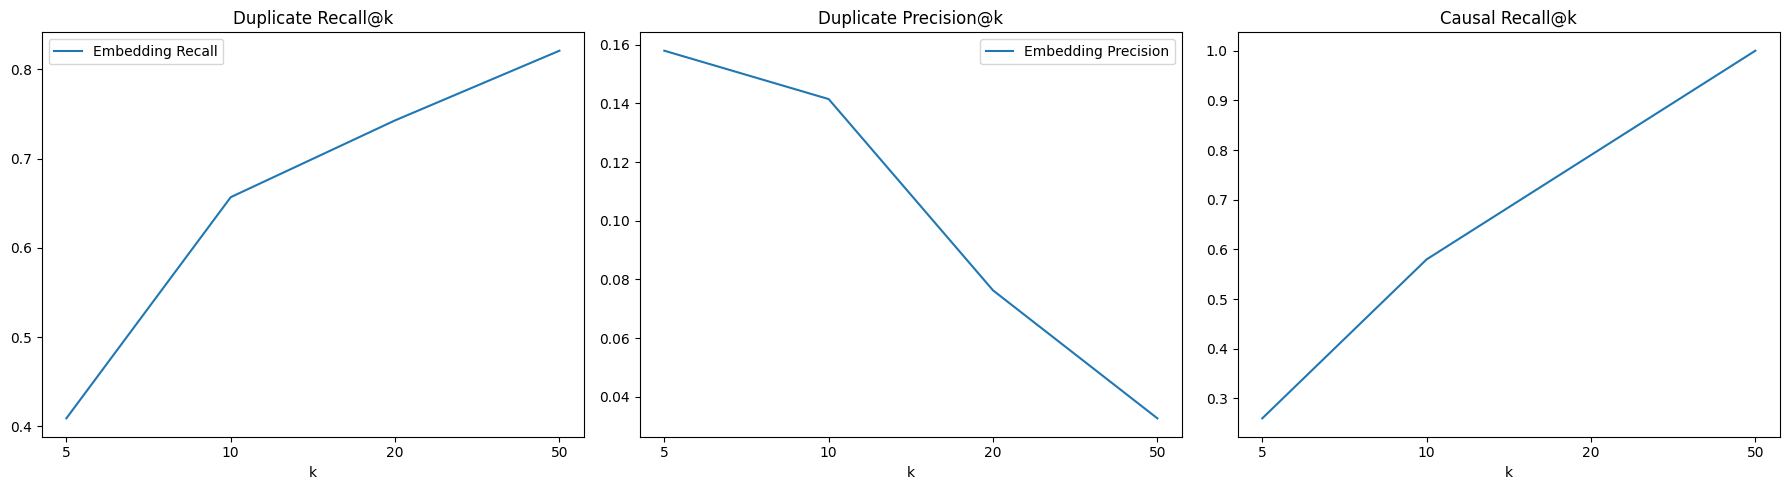

In [13]:
# Plot summaries
labels = [str(k) for k in K_VALUES]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(labels, [embed_summary[k]['recall'] for k in K_VALUES], label='Embedding Recall')
if rerank_summary is not None:
    axes[0].plot(labels, [rerank_summary[k]['recall'] for k in K_VALUES], label='Rerank Recall')
axes[0].set_title('Duplicate Recall@k')
axes[0].set_xlabel('k')
axes[0].legend()

axes[1].plot(labels, [embed_summary[k]['precision'] for k in K_VALUES], label='Embedding Precision')
if rerank_summary is not None:
    axes[1].plot(labels, [rerank_summary[k]['precision'] for k in K_VALUES], label='Rerank Precision')
axes[1].set_title('Duplicate Precision@k')
axes[1].set_xlabel('k')
axes[1].legend()

axes[2].plot(labels, [causal_recall[k] for k in K_VALUES], label='Causal Recall')
axes[2].set_title('Causal Recall@k')
axes[2].set_xlabel('k')

plt.tight_layout()
plt.show()
